<!-- 1:40 -->

# understanding <abbr title="accessible rich internet applications">aria</abbr> roles as python classes

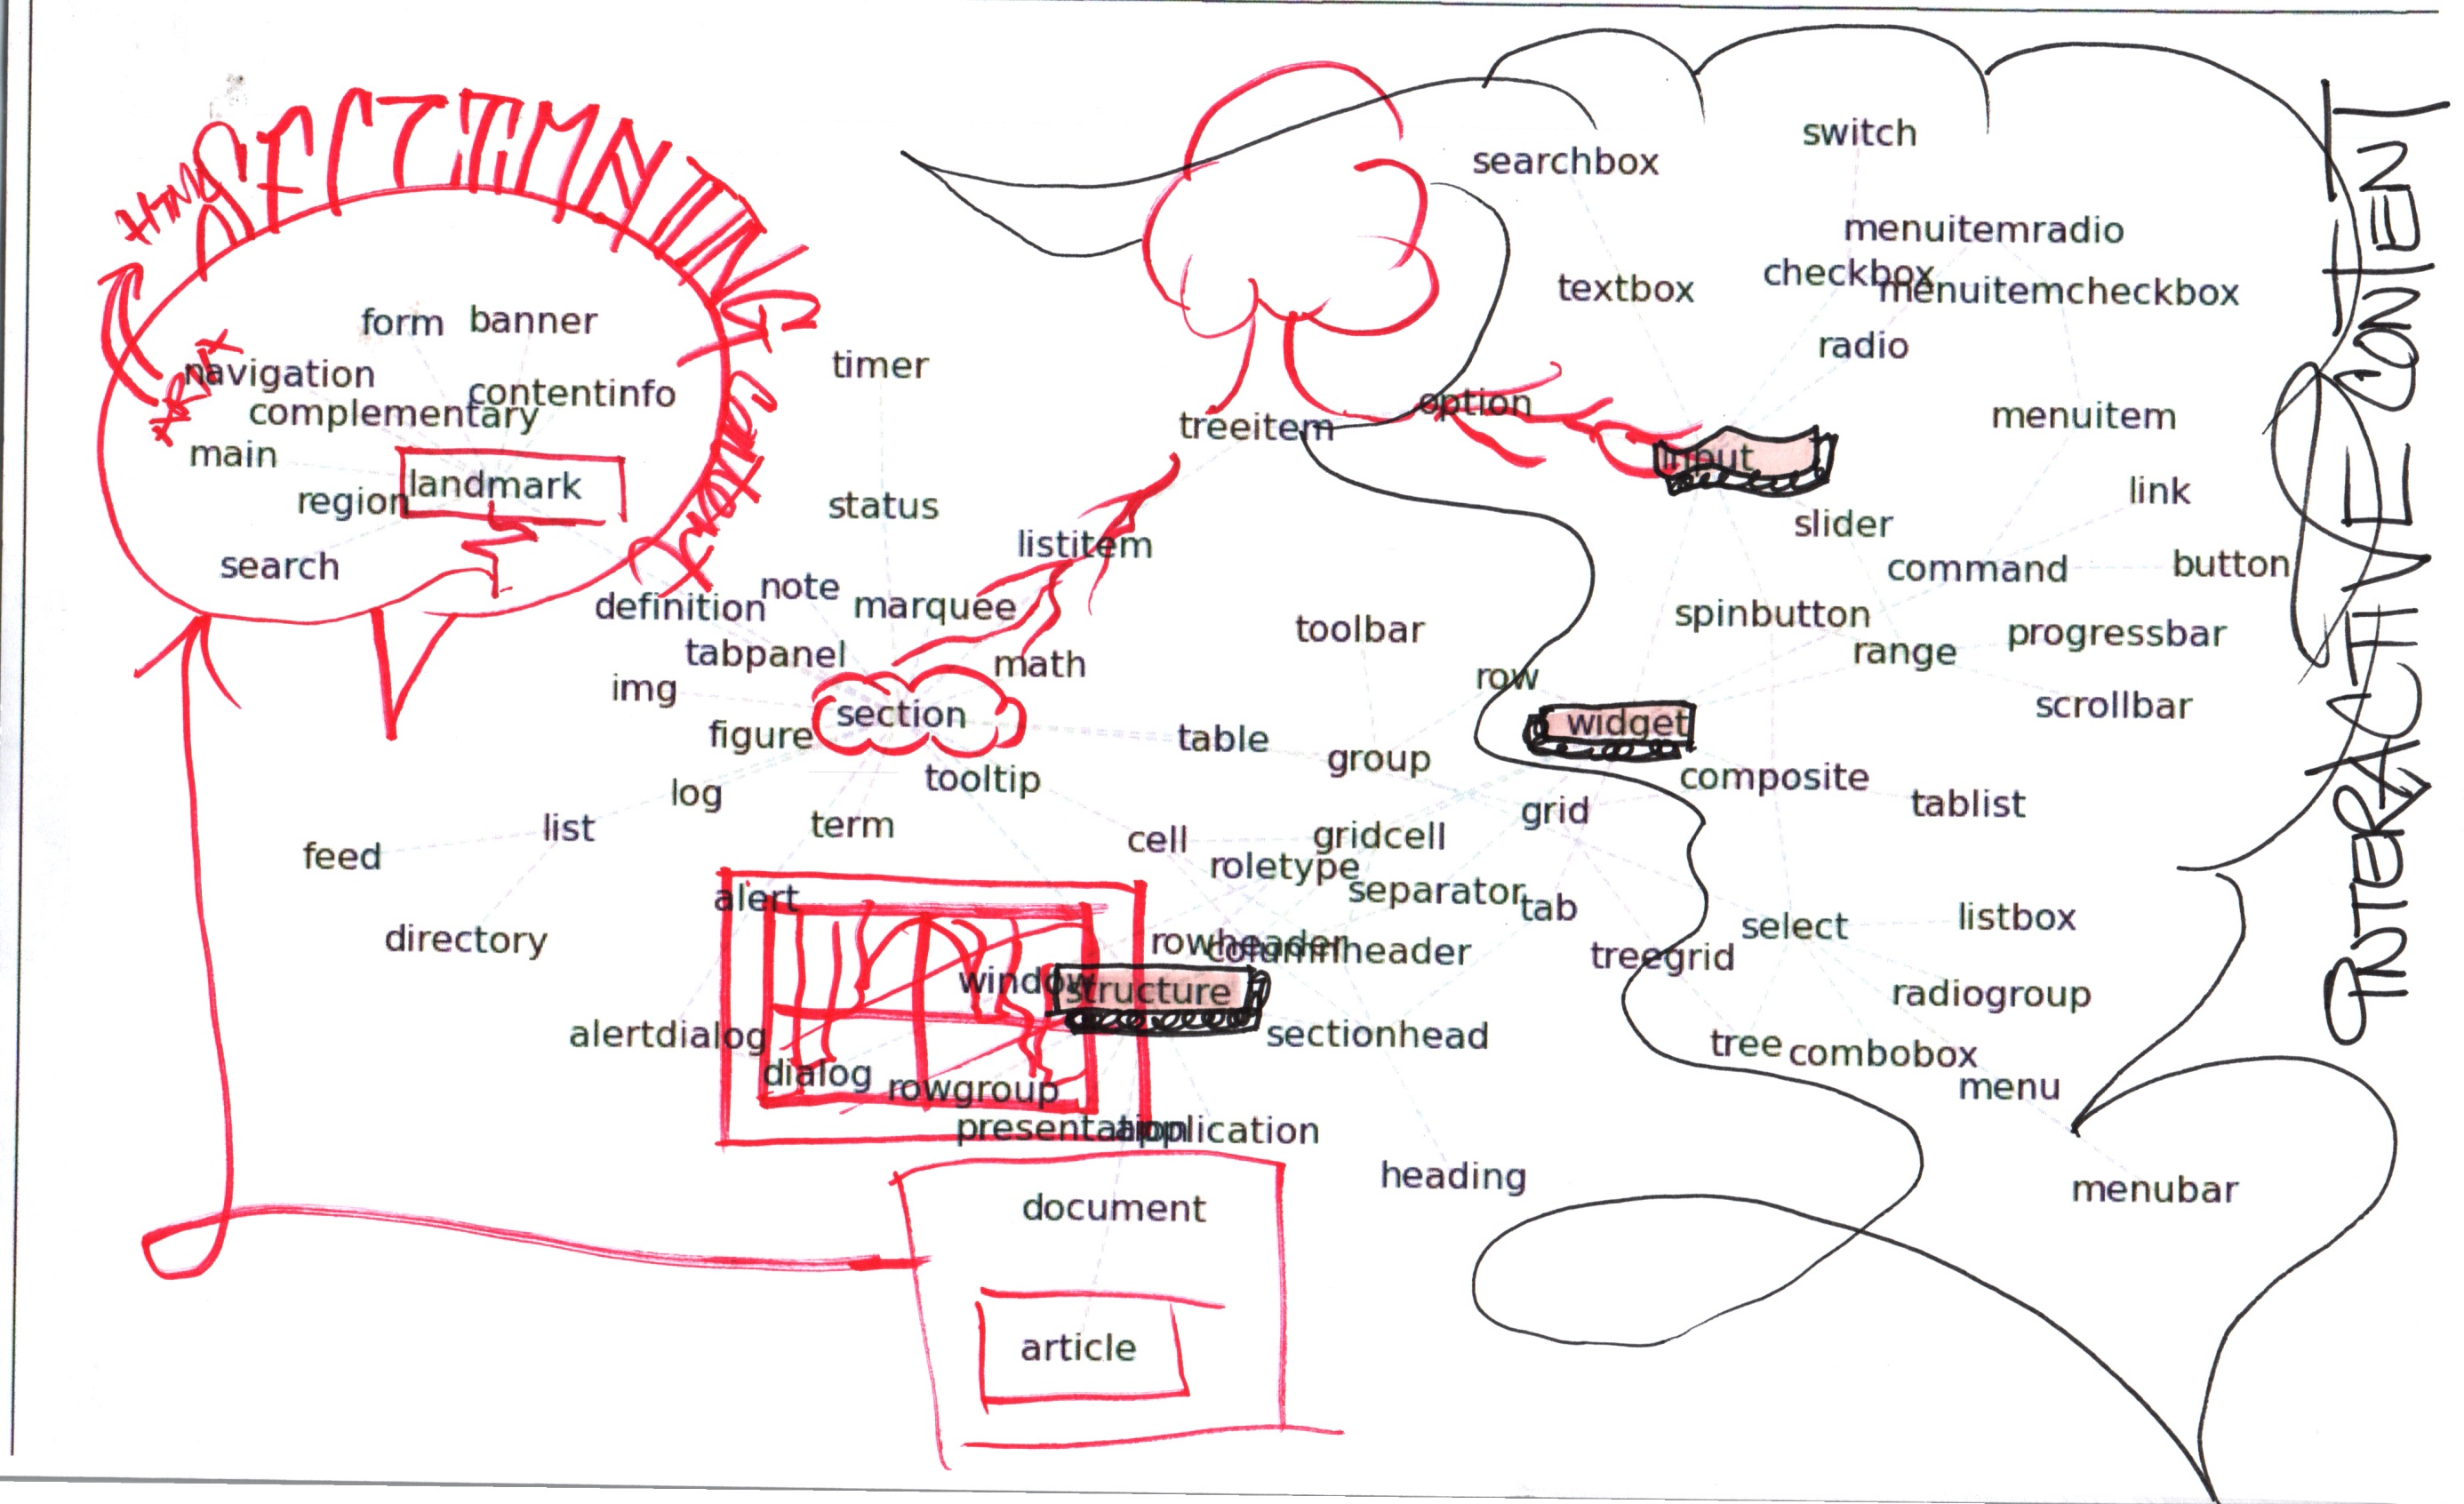

1. use `rdflib` to load in the aria data
2. use `networkx` and `matplotlib` to visual the ARIA role hierarchy
3. create python `dataclass` analogs of the ARIA roles

the goal is to learn by casting ARIA is ways i understand it: as data, code, and drawing.

## notebook recording

In [1]:
%%html
<iframe width="815" height="459" src="https://www.youtube.com/embed/ngUHOBAF604" title="accessible rich internet applications as programming concepts" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture; web-share" referrerpolicy="strict-origin-when-cross-origin" allowfullscreen></iframe>

In [30]:
from requests_cache import install_cache, requests
import rdflib
from rdflib.namespace import RDF, RDFS, OWL
from pandas import DataFrame, Series, Index
install_cache()

## discussion and illustration of the ARIA RDF 

In [32]:
graph = rdflib.Graph()
graph.parse(io.StringIO(requests.get("https://www.w3.org/WAI/ARIA/schemata/aria-1.rdf").text), format="xml")
ARIA = rdflib.Namespace("http://www.w3.org/WAI/ARIA/Schemata/aria-1#")
XHTML = rdflib.Namespace("http://www.w3.org/1999/xhtml/vocab#")

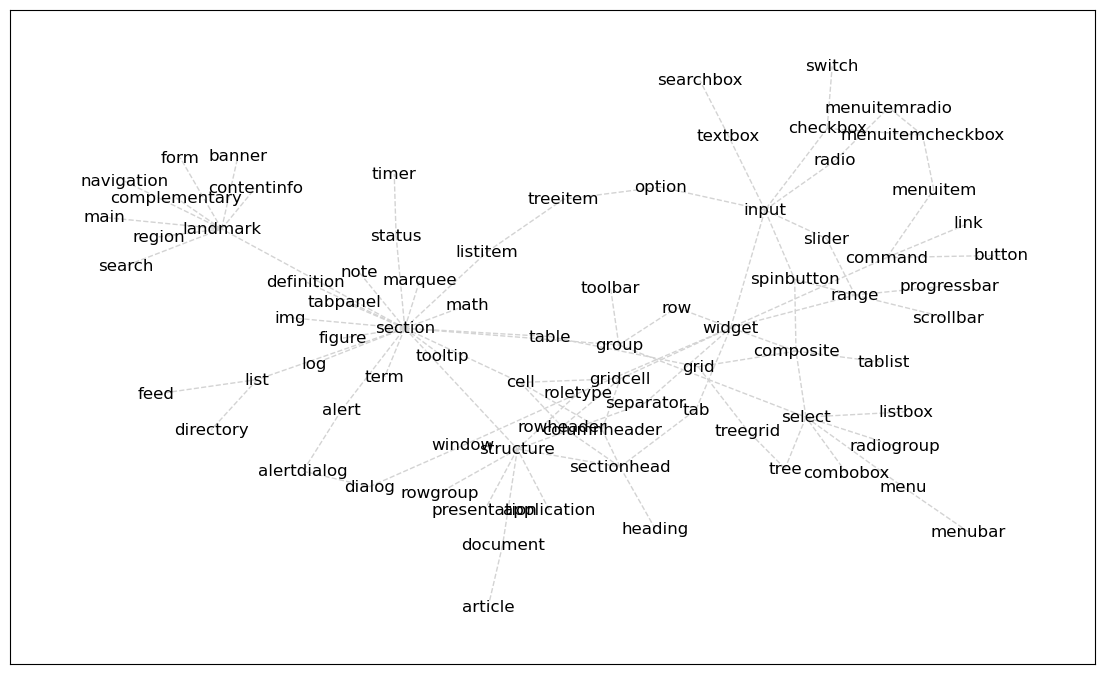

In [34]:
import matplotlib.pyplot as matplotlib

import networkx
nx = networkx.Graph()
edges= DataFrame(graph.subject_objects(RDFS.subClassOf)).stack().str.rpartition("#")[2].unstack()
edges = edges[edges.apply(lambda s: s.str.isalpha().all(), 1)]
nx.add_edges_from(edges.values)

# plot = networkx.draw_networkx(nx)
layout = networkx.nx_agraph.graphviz_layout(nx, "sfdp")
valmap(compose_left(reversed, tuple), layout)
networkx.draw_networkx(nx, layout, style="--", edge_color="lightgray", node_size=0)
matplotlib.gcf().set_size_inches(14, 8.5)

In [2]:
%%html
<iframe width="815" height="459" src="https://www.youtube.com/embed/tLau9HsknPY" title="drawing notes over a diagram of accessible rich internet applications properties" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture; web-share" referrerpolicy="strict-origin-when-cross-origin" allowfullscreen></iframe>

## create a pandas dataframe that will create the classes

In [8]:
    df = DataFrame(index=Index(x for x in graph.subjects(RDF.type, OWL.Class) if "://" in x))
    df = df.join(
        df.index.to_series().apply(
            lambda x: list(x for x in graph.objects(x, RDFS.subClassOf) if "://" in x)
        ).rename("subclass")
    ).join(
        df.index.to_series().apply(
            lambda x: list(x for x in graph.objects(x, XHTML.supportedState) if "://" in x)
        ).rename("property")
    ).join(
        df.index.to_series().apply(
            lambda x: "\n".join(x for x in graph.objects(x, RDFS.seeAlso))
        ).rename("doc")
    )

## create python classes

In [16]:
%%
    classes = {}
    class aria: 
base class for all of the python classes we make

    def get_class(role, subclasses=None, properties=None, doc="") -> dataclass: 
        if role in classes:
Skedaddle if the role is already defined

            return classes[role]

        if subclasses is None:
Initialize the default for some classes and properties if they weren't provided
            
            subclasses = df.loc[role].subclass
            properties = df.loc[role].property
            doc = df.loc[role].doc
Build the properties that we want to pass to our new Python aria type                
                
        property = dict(id=role, __annotations__={}, __doc__=doc)
        annotations = property["__annotations__"]

                    
        for prop in properties:
Accumulate the properties and their values. We have to define the default property value and the annotation type.
    
            key = prop.rpartition("#aria-")[2]
            property[key] = None
            annotations[key] = prop

        subs = tuple(
            get_class(x) for x in reversed(subclasses) if x != ARIA.roletype
        )
Reverse the sub classes, so Python can build the types properly; otherwise we get a module resolution error.

        if not subs:
The most abstract base classes will not have a sub class. This is where we use our aria class to track all of those we build.
                       
            subs = aria,
Create the type as a data class using the role is the class name, and attach it to the aria class and classes cache.
                
        t = dataclass(type(role.rpartition("#")[2], subs, property))
        setattr(aria, role.rpartition("#")[2], t)
        return classes.setdefault(role, t)

    for name, row in df.iterrows():
Iterate through the data frame, Rose and build all the classes.
Afterwards, we know all the possible aria names and we attach them to a close namespace that we can use to talk about the object objects.
    
        get_class(name, row.subclass, row.property)
    ns, sep, term = ARIA.roletype.rpartition("#")
    ARIA = rdflib.namespace.ClosedNamespace(ns + sep, Series(list(classes)).str.rpartition("#")[2])

classes = {}
class aria: 
 
 base class for all of the python classes we make 
 def get_class(role, subclasses=None, properties=None, doc="") -> dataclass: 
 if role in classes:
 
 Skedaddle if the role is already defined 
 return classes[role]

 if subclasses is None:
 
 Initialize the default for some classes and properties if they weren't provided 
 subclasses = df.loc[role].subclass
 properties = df.loc[role].property
 doc = df.loc[role].doc
 
 Build the properties that we want to pass to our new Python aria type 
 property = dict(id=role, __annotations__={}, __doc__=doc)
 annotations = property["__annotations__"]

 
 for prop in properties:
 
 Accumulate the properties and their values. We have to define the default property value and the annotation type. 
 key = prop.rpartition("#aria-")[2]
 property[key] = None
 annotations[key] = prop

 subs = tuple(
 get_class(x) for x in reversed(subclasses) if x != ARIA.roletype
 )
 
 Reverse the sub classes, so Python can build the types properly; otherwise we get a module resolution error. 
 if not subs:
 
 The most abstract base classes will not have a sub class. This is where we use our aria class to track all of those we build. 
 subs = aria,
 
 Create the type as a data class using the role is the class name, and attach it to the aria class and classes cache. 
 t = dataclass(type(role.rpartition("#")[2], subs, property))
 setattr(aria, role.rpartition("#")[2], t)
 return classes.setdefault(role, t)

for name, row in df.iterrows():
 
 Iterate through the data frame, Rose and build all the classes.
Afterwards, we know all the possible aria names and we attach them to a close namespace that we can use to talk about the object objects. 
 get_class(name, row.subclass, row.property)
ns, sep, term = ARIA.roletype.rpartition("#")
ARIA = rdflib.namespace.ClosedNamespace(ns + sep, Series(list(classes)).str.rpartition("#")[2])